##Мультиагентный сервис ответов на вопросы по данным продаж

# 📊 Мультиагентный сервис ответов на вопросы по данным продаж

## Проблема (конкретно)
Владелец небольшого интернет-магазина регулярно задаёт вопросы к выгрузке заказов:
- «Почему в марте просела выручка?»
- «Где у нас самый высокий процент возвратов?»
- «Какие категории реально приносят прибыль?»

Сегодня это решается одним из двух способов:
1. **Вручную в Excel или Google Sheets.** Это 1–2 часа на вопрос: сводные таблицы, формулы, проверка, текст вывода. Часто бывают ошибки в формулах и в разрезах.
2. **Через аналитика или подрядчика.** Ответ приходит через 1–2 рабочих дня, а час аналитика стоит около 1 500–3 000 ₽.

## Пользователь и текущие затраты
> ⚠️ Цифры ниже — **рабочие допущения для расчёта**.

| Параметр | Значение |
|---|---|
| Пользователь | владелец  малого бизнеса (500–5 000 заказов в месяц) |
| Частота вопросов | ~3–5 в неделю |
| Время на 1 вопрос сегодня | ~1,5 часа (Excel) или ~1–2 дня ожидания (аналитик) |
| Стоимость сегодня | 4 ч/нед × 4 нед × ~1 500 ₽/ч ≈ **24 000 ₽/мес** времени одного сотрудника |

## Метрики, которые улучшаем

| Метрика | Сегодня | Цель |
|---|---|---|
| Время «вопрос → готовый вывод» | 60–90 мин | **≤ 5 мин** |
| Доля чисел в отчёте, подтверждённых расчётом | не измеряется (ошибки вручную) | **≥ 90 %** (проверяется автоматически) |
| Доля верных ключевых фактов (сверка с эталоном) | — | **выше, чем у одного агента** (измеряем ниже) |
| Стоимость запроса | ~2 000 ₽ | ~0 ₽ (локальная модель) |

## Почему нельзя обойтись одним агентом
Один LLM, который «и код пишет, и выводы делает», на практике ведёт себя так:
- пишет код с ошибкой или молча считает не то;
- выдумывает числа в тексте отчёта, которых нет в результатах расчёта;
- не умеет сказать «в данных этого нет» и подменяет метрику похожей.

Поэтому роли разделены:

| Агент | Роль | Инструменты | Зачем отдельно |
|---|---|---|---|
| 🧭 **Planner** | Разбивает вопрос бизнеса на 2–4 аналитических шага | `dataset_profile` | Явный план не даёт потерять часть вопроса |
| 🧮 **Analyst** | Пишет и выполняет pandas-код | `dataset_profile`, `run_python` | Специализация на коде, исправляет ошибки по обратной связи |
| 🔍 **Reviewer** | Критикует расчёт и возвращает его Analyst'у | (правила и LLM) | Независимый взгляд: пустой вывод, NaN, не покрыт шаг плана, ошибка выполнения |
| ✍️ **Writer** | Пишет отчёт для нетехнического читателя | — | Разделение «посчитать» и «объяснить» |
| 🛡 **Auditor** | Проверяет, что каждое число в отчёте есть в расчёте, и возвращает отчёт Writer'у | `verify_numbers` | Защита от галлюцинаций цифр |

## Архитектура графа

```
                    вопрос
                      │
                      ▼
               ┌────────────┐
               │  Planner   │ ── данных нет (напр. NPS) ──────────┐
               └─────┬──────┘                                     │
                     │ данные есть: план из 2–4 шагов             │
                     ▼                                            │
               ┌────────────┐   tools: dataset_profile, run_python│
      ┌──────► │  Analyst   │                                     │
      │        └─────┬──────┘                                     │
      │ revise       ▼                                            │
      │ (iter<3) ┌────────────┐                                   │
      └───────── │  Reviewer  │                                   │
                 └─────┬──────┘                                   │
                       │ approve (или лимит итераций)             │
                       ▼                                          │
               ┌────────────┐ ◄─────────────────────────────────┘
      ┌──────► │   Writer   │
      │        └─────┬──────┘
      │ revise       ▼
      │ (iter<2) ┌────────────┐   tool: verify_numbers
      └───────── │  Auditor   │
                 └─────┬──────┘
                       │ ok (или лимит итераций)
                       ▼
                      END
```

### Куда передаётся управление

| Из узла | В узел | Условие |
|---|---|---|
| Planner | Analyst | нужные данные есть в колонках `df`, составлен план |
| Planner | Writer | нужной метрики нет в данных (например, NPS): Analyst и Reviewer пропускаются |
| Analyst | Reviewer | всегда (после каждого расчёта) |
| Reviewer | Analyst | **цикл №1**: код упал, вывод пустой, есть NaN или расчёт не отвечает на вопрос, и лимит попыток не исчерпан |
| Reviewer | Writer | расчёт одобрен **или** исчерпан `MAX_ANALYSIS_ITERS` (тогда в итоге будет `WARN`) |
| Writer | Auditor | всегда (после каждой версии отчёта) |
| Auditor | Writer | **цикл №2**: в отчёте есть числа, которых нет в расчёте, или замечание по сути, и лимит версий не исчерпан |
| Auditor | END | отчёт принят **или** исчерпан `MAX_REPORT_ITERS` / `MAX_TOTAL_STEPS` |

### Два цикла обратной связи

1. **Reviewer → Analyst** (качество расчёта). Analyst получает свой прошлый код, текст ошибки с номером строки и подсказку по типовой ошибке pandas.
2. **Auditor → Writer** (качество отчёта). Writer получает свой прошлый текст и список замечаний.

### Особые случаи

| Ситуация | Что делает система |
|---|---|
| Данных для ответа нет | Planner передаёт управление Writer'у с пометкой `НЕТ ДАННЫХ: …`, отчёт объясняет, что нужно собрать |
| Расчёт не выполнился после всех попыток | Writer не обращается к LLM и выдаёт шаблонный отчёт «расчёт не выполнен из-за технической ошибки», чтобы модель не выдумала цифры |
| Writer не изменил отчёт после замечания | повторная LLM-проверка пропускается, граф завершается со статусом `WARN` |

### Защита от зацикливания (три уровня)

| Уровень | Параметр | Значение | Что ограничивает |
|---|---|---|---|
| 1 | `MAX_ANALYSIS_ITERS` | 3 | число попыток Analyst (цикл №1) |
| 1 | `MAX_REPORT_ITERS` | 2 | число версий отчёта (цикл №2) |
| 2 | `MAX_TOTAL_STEPS` | 14 | общее число шагов графа, сумма по всем узлам |
| 3 | `recursion_limit` | 30 | аварийный предохранитель LangGraph |

При исчерпании лимита система **не зависает, а выдаёт результат со статусом `WARN`** и пояснением, что именно не удалось довести до конца.

### Статусы результата

| Статус | Значение |
|---|---|
| `OK` | расчёт одобрен Reviewer'ом, числа отчёта подтверждены, замечаний нет |
| `WARN: расчёт не прошёл ревью полностью…` | достигнут лимит попыток Analyst, цифры требуют перепроверки |
| `WARN: числа подтверждены, но остались замечания аудитора` | детерминированная проверка прошла, но LLM-аудитор остался недоволен |
| `WARN: числа подтверждены, но замечание аудитора не привело к изменению отчёта` | Writer выдал тот же текст, автоматически считать его верным нельзя |
| `WARN: в отчёте остались непроверенные числа` | в отчёте есть числа, которых нет в результатах расчёта |
| Расчёт выполнился, но Reviewer не одобрил его после всех попыток | Writer не обращается к LLM и выдаёт шаблонный отчёт с замечанием ревьюера, неподтверждённые цифры не публикуются; статус `WARN` |

## Установка и запуск Ollama

| Ресурсы | Модель | Комментарий |
|---|---|---|
| GPU T4 (рекомендуется) | `qwen2.5:7b-instruct` (~4,7 ГБ) | хороший код и русский язык, ~20–30 ток/с |


In [50]:
!pip -q install -U langgraph langchain-ollama langchain-core pydantic pandas matplotlib ipywidgets
!apt-get -qq install -y zstd pciutils > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh
!nvidia-smi -L || echo "GPU не найден — используйте модель qwen2.5:3b"

>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.
GPU 0: Tesla T4 (UUID: GPU-d9df606a-d490-95d4-025d-5fa7ca59cd26)


In [51]:
import subprocess, requests, time

subprocess.Popen(["ollama", "serve"],
                 stdout=open("/content/ollama.log", "w"), stderr=subprocess.STDOUT)
for _ in range(60):
    try:
        requests.get("http://127.0.0.1:11434", timeout=1)
        print("✅ Ollama запущен")
        break
    except Exception:
        time.sleep(1)

MODEL = "qwen2.5:7b-instruct"      # для CPU поставьте "qwen2.5:3b"
!ollama pull {MODEL}

✅ Ollama запущен



## Описание синтетического датасета

Таблица `DF` генерируется. Одна строка — один заказ, в заказе одна позиция (одна категория).

### Общие параметры

| Параметр | Значение |
|---|---|
| Исходное число заказов | 6 000 |
| После удаления «поломки сайта» | ≈ 5 700–5 750 (точное число выводит `DF.shape`) |
| Период | 1 января — 30 июня 2024 (182 дня) |
| Число колонок | 13 |
| Валюта | ₽ |
| Пропуски (NaN) и дубликаты | отсутствуют |

### Переменные

| Колонка | Что означает | Тип | Как генерируется | Диапазон / значения |
|---|---|---|---|---|
| `order_id` | Уникальный номер заказа. Присваивается после сортировки по дате, поэтому более ранние заказы имеют меньший номер | int | сквозная нумерация | 1 … N |
| `order_date` | Дата оформления заказа. По ней строятся динамика по месяцам и сравнение периодов | datetime | равномерно по 182 дням | 2024-01-01 … 2024-06-30 |
| `customer_id` | Идентификатор покупателя. Нужен, чтобы отличать клиентов друг от друга. Повторных покупок почти нет, лояльность по нему анализировать нельзя | int | случайно, равномерно | 1 … 2 499 |
| `category` | Категория купленного товара. Основной разрез для вопросов о прибыли, марже и возвратах | str | случайно с весами по категориям | Электроника, Одежда, Дом и сад, Косметика, Спорт, Книги |
| `channel` | Канал продаж: где клиент оформил заказ (свой сайт, маркетплейс, соцсеть, магазин) | str | случайно с весами по каналам | Сайт, Маркетплейс, Instagram, Офлайн |
| `region` | Регион доставки: в какой город доставлен заказ. В данных не заложено закономерностей, поэтому результаты по регионам получаются «ровными» | str | равномерно | Москва, Санкт-Петербург, Казань, Новосибирск, Екатеринбург |
| `quantity` | Сколько штук товара в заказе | int | 1 шт. — 70 %, 2 шт. — 20 %, 3 шт. — 10 % | 1, 2, 3 |
| `unit_price` | Цена одной штуки **до скидки**, в рублях | float | средняя цена категории × логнормальный шум (σ = 0,25), округление до рубля | зависит от категории (от сотен до десятков тысяч ₽) |
| `discount` | Скидка на заказ как **доля** от цены: 0,1 означает 10 %. Для процентов умножайте на 100 | float | 0 — 45 %, 0,05 — 20 %, 0,10 — 20 %, 0,20 — 10 %, 0,30 — 5 % | 0 … 0,3 |
| `unit_cost` | Себестоимость одной штуки для магазина (сколько стоил товар), в рублях. Нужна для расчёта прибыли | float | `unit_price` × доля себестоимости категории × случайный множитель 0,95–1,05 | зависит от категории |
| `returned` | Признак возврата: **1** — клиент вернул заказ, **0** — не вернул. Среднее значение колонки равно доле возвратов | int (0/1) | случайно с вероятностью возврата, зависящей от категории и канала | 0 или 1 |
| `revenue` | Выручка по заказу после скидки, в рублях. Уже посчитана, пересчитывать не нужно. **Не уменьшается на возвраты** | float | `quantity × unit_price × (1 − discount)` | > 0 |
| `profit` | Валовая прибыль по заказу, в рублях: выручка минус себестоимость проданных штук. Уже посчитана. Не учитывает рекламу, доставку, комиссии и возвраты | float | `revenue − quantity × unit_cost` | может быть < 0 |

### Как связаны колонки

| Что нужно получить | Из каких колонок | Формула |
|---|---|---|
| Выручка | `revenue` | `sum(revenue)` |
| Прибыль | `profit` | `sum(profit)` |
| Маржа, % | `profit`, `revenue` | `sum(profit) / sum(revenue) × 100` |
| Доля возвратов, % | `returned` | `mean(returned) × 100` |
| Средний чек | `revenue` | `mean(revenue)` |
| Месяц заказа | `order_date` | `order_date.dt.month` |
| Размер скидки в % | `discount` | `discount × 100` |

### Частые ошибки при работе с колонками

| Ошибка | Почему это неверно |
|---|---|
| Считать выручку как `unit_price × quantity` | не учтена скидка, правильно брать готовую колонку `revenue` |
| Считать прибыль как `revenue − unit_cost` | себестоимость нужно умножать на `quantity`, правильно брать готовую колонку `profit` |
| Считать долю возвратов как `sum(returned)` | это число возвратов, а не доля; долю даёт `mean(returned) × 100` |
| Считать потери от возвратов как `revenue` по возвращённым заказам, ожидая, что она уже вычтена | в данных `revenue` и `profit` не корректируются на возвраты |
| Искать в данных NPS, отзывы или оценки | таких колонок нет, правильный ответ системы — честный отказ |

### Параметры категорий

| Категория | Доля заказов | Средняя цена, ₽ | Себестоимость (доля от цены) | Базовая вероятность возврата |
|---|---|---|---|---|
| Электроника | 14 % | 15 000 | 70 % | 5 % (30 % в маркетплейсе) |
| Одежда | 24 % | 3 000 | 55 % | 12 % |
| Дом и сад | 18 % | 2 500 | 60 % | 5 % |
| Косметика | 20 % | 1 200 | 45 % | 5 % |
| Спорт | 12 % | 4 000 | 62 % | 5 % |
| Книги | 12 % | 700 | 65 % | 5 % |

### Каналы продаж

| Канал | Доля заказов |
|---|---|
| Сайт | 40 % |
| Маркетплейс | 30 % |
| Instagram | 20 % |
| Офлайн | 10 % |

### Заложенные закономерности (то, что агенты должны найти)

| № | Закономерность | Как заложена | Ожидаемый результат |
|---|---|---|---|
| 1 | **Падение канала «Сайт» в марте** | случайные 65 % заказов канала «Сайт» за март удалены | выручка «Сайта» в марте ниже февраля примерно на 60–70 %; общая выручка падает примерно на 25 %; остальные каналы стабильны |
| 2 | **Аномальные возвраты** | вероятность возврата в связке «Электроника × Маркетплейс» 30 % вместо 5 % | эта связка лидирует по проценту возвратов (≈ 30 %); у «Одежды» ≈ 12 % |
| 3 | **Разная маржинальность категорий** | разная доля себестоимости | по прибыли лидирует «Электроника», затем «Одежда»; третье место делят «Дом и сад» и «Спорт» (их прибыль близка, победитель зависит от случайного шума) |
| 4 | **Отсутствующие данные** | в таблице нет колонок с оценками клиентов | запрос про NPS должен закончиться честным отказом |

### Метрики, которые считаются по таблице

| Метрика | Формула |
|---|---|
| Выручка | `sum(revenue)` |
| Прибыль | `sum(profit)` |
| Маржа, % | `sum(profit) / sum(revenue) × 100` |
| Доля возвратов, % | `mean(returned) × 100` |
| Средний чек | `mean(revenue)` |
| Динамика по месяцам | `revenue` по `order_date.dt.month`, изменение в % к предыдущему месяцу |

### Ограничения датасета

| Ограничение | Что это значит |
|---|---|
| Данные синтетические | реальных клиентов и продаж нет; результаты нельзя переносить на настоящий бизнес |
| Нет сезонности и дней недели | даты распределены равномерно, единственная «аномалия» — март по каналу «Сайт» |
| Месяцы неравны по длине | в феврале 29 дней, в марте 31, поэтому небольшая разница выручки есть и без поломки |
| Переменные независимы | регион, скидка и клиент не влияют на цену, возвраты и категорию |
| `region` не содержит закономерностей | вопросы про регионы должны давать «ровные» результаты |
| `customer_id` случайный | нет лояльных и разовых клиентов, когорты и LTV считать бессмысленно |
| Возвраты не влияют на деньги | `revenue` и `profit` не уменьшаются на возвращённые заказы, возвраты только помечены флагом `returned` |
| Отрицательная прибыль встречается редко | только у «Электроники» со скидкой 30 % (себестоимость близка к цене со скидкой) |
| Нет прочих издержек | нет рекламных расходов, доставки, комиссий маркетплейса и налогов, `profit` — валовая прибыль |
| Один товар в заказе | в заказе нет корзины из нескольких категорий |
| Идеально чистые данные | нет пропусков, дублей и опечаток; на реальных данных нужна очистка |
| Нет оценок клиентов | NPS, CSAT и отзывы отсутствуют (нужно для сценария «честного отказа») |
| Небольшой объём | около 5 700 строк, достаточно для демонстрации, но не для статистических выводов |

In [52]:
#Импорты, синтетические данные
import os, re, io, json, time, operator, contextlib, builtins, traceback
from typing import TypedDict, Annotated, Literal
import numpy as np
import pandas as pd
from pydantic import BaseModel, Field
from langchain_ollama import ChatOllama
from langchain_core.tools import tool
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from IPython.display import display, Markdown, Image

# ---------- Конфиг и защита от зацикливания ----------
MAX_ANALYSIS_ITERS = 3     # макс. попыток Analyst
MAX_REPORT_ITERS   = 2     # макс. версий отчёта
MAX_TOTAL_STEPS    = 14    # глобальный лимит шагов графа
NUM_SUPPORT_THRESHOLD = 0.9
VERBOSE = True
FORCE_REJECT = ""          # "", "reviewer" или "auditor" — для теста защиты от зацикливания

# ---------- Синтетические данные ----------
rng = np.random.default_rng(42)
N = 6000
CATS = {  # категория: (средняя цена, доля себестоимости, вес)
    "Электроника": (15000, 0.70, 0.14), "Одежда": (3000, 0.55, 0.24),
    "Дом и сад": (2500, 0.60, 0.18),    "Косметика": (1200, 0.45, 0.20),
    "Спорт": (4000, 0.62, 0.12),        "Книги": (700, 0.65, 0.12)}
CHANNELS = {"Сайт": 0.40, "Маркетплейс": 0.30, "Instagram": 0.20, "Офлайн": 0.10}
REGIONS = ["Москва", "Санкт-Петербург", "Казань", "Новосибирск", "Екатеринбург"]

cat = rng.choice(list(CATS), N, p=[v[2] for v in CATS.values()])
ch = rng.choice(list(CHANNELS), N, p=list(CHANNELS.values()))
base = np.array([CATS[c][0] for c in cat])
share = np.array([CATS[c][1] for c in cat])
unit_price = (base * rng.lognormal(0, 0.25, N)).round(0)
unit_cost = (unit_price * share * rng.uniform(0.95, 1.05, N)).round(0)
qty = rng.choice([1, 2, 3], N, p=[0.7, 0.2, 0.1])
disc = rng.choice([0, 0.05, 0.1, 0.2, 0.3], N, p=[0.45, 0.2, 0.2, 0.1, 0.05])
p_ret = np.where(cat == "Одежда", 0.12, 0.05)
p_ret = np.where((cat == "Электроника") & (ch == "Маркетплейс"), 0.30, p_ret)

DF = pd.DataFrame({
    "order_date": pd.Timestamp("2024-01-01") + pd.to_timedelta(rng.integers(0, 182, N), unit="D"),
    "customer_id": rng.integers(1, 2500, N), "category": cat, "channel": ch,
    "region": rng.choice(REGIONS, N), "quantity": qty, "unit_price": unit_price,
    "discount": disc, "unit_cost": unit_cost, "returned": (rng.random(N) < p_ret).astype(int)})
DF["revenue"] = (DF.quantity * DF.unit_price * (1 - DF.discount)).round(2)
DF["profit"] = (DF.revenue - DF.quantity * DF.unit_cost).round(2)

# закладываем «поломку сайта» в марте
mask = (DF.channel == "Сайт") & (DF.order_date.dt.month == 3) & (rng.random(len(DF)) < 0.65)
DF = DF[~mask].sort_values("order_date").reset_index(drop=True)
DF.insert(0, "order_id", np.arange(1, len(DF) + 1))

print(DF.shape); DF.head()

(5756, 13)


,order_id,order_date,customer_id,category,channel,region,quantity,unit_price,discount,unit_cost,returned,revenue,profit
0,1,2024-01-01,2300,Электроника,Сайт,Казань,3,19329.0,0.2,13222.0,0,46389.6,6723.6
1,2,2024-01-01,655,Косметика,Маркетплейс,Екатеринбург,1,1580.0,0.0,687.0,0,1580.0,893.0
2,3,2024-01-01,239,Электроника,Instagram,Санкт-Петербург,2,14032.0,0.0,10070.0,0,28064.0,7924.0
3,4,2024-01-01,1631,Книги,Маркетплейс,Санкт-Петербург,1,471.0,0.1,321.0,0,423.9,102.9
4,5,2024-01-01,247,Дом и сад,Сайт,Екатеринбург,3,2554.0,0.2,1516.0,0,6129.6,1581.6


##Инструменты (tools)

Инструментов три:

    dataset_profile: описание таблицы (схема, значения, примеры).
    run_python: выполнение pandas-кода в ограниченной среде.
    verify_numbers: детерминированная проверка, что каждое число отчёта есть в результатах расчёта.

    ℹ️ Инструменты вызываются узлами графа явно, а не через function calling. Для 7B-моделей это надёжнее: нет риска, что модель сломает формат tool-call.
    ⚠️ run_python ограничивает импорты и встроенные функции. В продакшене нужен контейнер или внешний сервис (E2B, Docker).


In [53]:
COLUMN_NOTES = {
    "order_id": "ID заказа",
    "order_date": "дата заказа (datetime)",
    "customer_id": "ID клиента",
    "category": "категория товара",
    "channel": "канал продаж",
    "region": "регион доставки заказа (город покупателя)",
    "quantity": "штук в заказе",
    "unit_price": "цена за штуку до скидки, ₽",
    "discount": "скидка (доля 0–0.3, например 0.1 = 10%)",
    "unit_cost": "себестоимость штуки, ₽",
    "returned": "1 = клиент вернул заказ, 0 = не вернул (на revenue и profit не влияет)",
    "revenue": "выручка = quantity*unit_price*(1-discount), ₽ (уже посчитана)",
    "profit": "прибыль = revenue - quantity*unit_cost, ₽ (уже посчитана; на возвраты НЕ скорректирована)"}

@tool
def dataset_profile() -> str:
    """Описание таблицы заказов df: колонки, типы, диапазон дат, значения категорий, примеры строк."""
    lines = [f"df — таблица заказов: {len(DF)} строк. Период: {DF.order_date.min().date()} — {DF.order_date.max().date()}",
             "Колонки:"]
    for c in DF.columns:
        extra = ""
        if DF[c].dtype == object or str(DF[c].dtype).startswith("str"):
            extra = " Значения: " + ", ".join(sorted(DF[c].unique())[:10])
        lines.append(f"- {c} ({DF[c].dtype}): {COLUMN_NOTES.get(c, '')}{extra}")
    lines.append("- month (int): номер месяца заказа 1–12, вычисляется из order_date (февраль = 2, март = 3). "
                 "Колонка уже есть в df внутри run_python, создавать её не нужно")
    lines.append("Пример строк:\n" + DF.assign(month=DF.order_date.dt.month).head(3).to_string())
    return "\n".join(lines)

# --- безопасное-ish выполнение кода ---
ALLOWED_MODULES = {"pandas", "numpy", "math", "datetime", "statistics"}
def _safe_import(name, *a, **k):
    if name.split(".")[0] not in ALLOWED_MODULES:
        raise ImportError(f"Импорт модуля '{name}' запрещён")
    return builtins.__import__(name, *a, **k)
SAFE_BUILTINS = {k: v for k, v in vars(builtins).items()
                 if k not in {"open", "exec", "eval", "compile", "input", "breakpoint", "exit", "quit"}}
SAFE_BUILTINS["__import__"] = _safe_import
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

@tool
def run_python(code: str) -> dict:
    """Выполняет pandas-код. Доступны df, pd, np. Результат нужно выводить через print().
    Возвращает {'ok': bool, 'output': str}."""
    buf = io.StringIO()
    env = {"__builtins__": SAFE_BUILTINS, "df": DF.assign(month=DF.order_date.dt.month), "pd": pd, "np": np}
    try:
        with contextlib.redirect_stdout(buf):
            exec(code, env)
        return {"ok": True, "output": buf.getvalue()[:6000]}
    except Exception as e:
        tb = traceback.format_exc()
        lines = code.splitlines()
        found = re.findall(r'File "<string>", line (\d+)', tb)
        where = ""
        if found:
            n = int(found[-1])
            if 1 <= n <= len(lines):
                where = f"Упало на строке {n} кода: {lines[n-1].strip()}\n"
        return {"ok": False,
                "output": (buf.getvalue()[-500:] + "\n" + where + f"{type(e).__name__}: {e}").strip()}

# --- проверка чисел ---
NUM_RE = re.compile(r"\d{1,3}(?:,\d{3})+(?:\.\d+)?"                      # 2,001,916.05
                    r"|\d+(?:[ \u00a0\u202f]\d{3})+(?:[.,]\d+)?"         # 4 226 115
                    r"|\d+(?:[.,]\d+)?")                                 # 12,01 / 12.01
SIMPLE_RE = re.compile(r"\d+(?:\.\d+)?")

def _to_float(s):
    s = re.sub(r"[ \u00a0\u202f]", "", s)
    if re.fullmatch(r"\d{1,3}(,\d{3})+(\.\d+)?", s):    # запятая как разделитель тысяч
        s = s.replace(",", "")
    else:                                                # запятая как десятичный знак
        s = s.replace(",", ".")
    return float(s)

def extract_numbers(text, grouped=True):
    rx = NUM_RE if grouped else SIMPLE_RE
    return [(m.group(), _to_float(m.group())) for m in rx.finditer(text)]

def _is_trivial(x):  # маленькие целые (номера шагов, месяцы) и годы не проверяем
    return float(x).is_integer() and (x <= 31 or 1900 <= x <= 2100)

def _supported(x, pool):
    for y in pool:
        for z in {y, y * 100 if y <= 1.5 else y, y / 1e3, y / 1e6}:
            if abs(x - z) <= max(0.02 * abs(z), 0.06):
                return True
    return False

@tool
def verify_numbers(report: str, source: str) -> dict:
    """Проверяет, что каждое нетривиальное число из отчёта присутствует в результатах расчёта (source)."""
    pool = {abs(v) for _, v in extract_numbers(source, True)} | {abs(v) for _, v in extract_numbers(source, False)}
    checked = [(raw, v) for raw, v in extract_numbers(report, True) if not _is_trivial(v)]
    bad = [raw for raw, v in checked if not _supported(v, pool)]
    total = len(checked)
    return {"total": total, "supported": total - len(bad),
            "ratio": 1.0 if total == 0 else (total - len(bad)) / total, "unsupported": bad}

# быстрый тест инструментов
print(dataset_profile.invoke({}))                      # полный профиль, без обрезки

res = run_python.invoke({"code": "print(df.groupby('channel').revenue.sum().round(0))"})
print("\nok:", res["ok"])
print(res["output"])                                   # только текст, переносы настоящие

bad = run_python.invoke({"code": "x = df.size()\nprint(x)"})   # проверка: ошибка должна показать номер строки
print("\nТест ошибки →", bad["output"])

print("\n", verify_numbers.invoke({"report": "Выручка 1 234 567 и 99999", "source": "revenue 1234567.0"}))
print(verify_numbers.invoke({"report": "Сайт: 2,895,967.35 ₽, итого 4 226 115 ₽, возвраты 12,01%",
                             "source": "2895967.35 4226115.0 12.01"}))
# ожидается: total=3, supported=3, unsupported=[]

df — таблица заказов: 5756 строк. Период: 2024-01-01 — 2024-06-30
Колонки:
- order_id (int64): ID заказа
- order_date (datetime64[us]): дата заказа (datetime)
- customer_id (int64): ID клиента
- category (str): категория товара Значения: Дом и сад, Книги, Косметика, Одежда, Спорт, Электроника
- channel (str): канал продаж Значения: Instagram, Маркетплейс, Офлайн, Сайт
- region (str): регион доставки заказа (город покупателя) Значения: Екатеринбург, Казань, Москва, Новосибирск, Санкт-Петербург
- quantity (int64): штук в заказе
- unit_price (float64): цена за штуку до скидки, ₽
- discount (float64): скидка (доля 0–0.3, например 0.1 = 10%)
- unit_cost (float64): себестоимость штуки, ₽
- returned (int64): 1 = клиент вернул заказ, 0 = не вернул (на revenue и profit не влияет)
- revenue (float64): выручка = quantity*unit_price*(1-discount), ₽ (уже посчитана)
- profit (float64): прибыль = revenue - quantity*unit_cost, ₽ (уже посчитана; на возвраты НЕ скорректирована)
- month (int): номер меся

#State (TypedDict), LLM

In [54]:
class AgentState(TypedDict, total=False):
    question: str                 # вопрос бизнеса
    plan: list[str]               # план от Planner
    code: str                     # последний код Analyst
    exec_ok: bool                 # код выполнился без ошибок
    exec_output: str              # stdout кода (результаты расчёта)
    analysis_feedback: str        # замечания Reviewer → Analyst
    analysis_iter: int            # счётчик попыток Analyst
    analysis_approved: bool
    report: str                   # текст отчёта
    prev_report: str              # предыдущая версия отчёта (для детекта «пустого» цикла)
    report_feedback: str          # замечания Auditor → Writer
    report_iter: int              # счётчик версий отчёта
    unsupported_numbers: list[str]
    next_step: str                # куда передать управление
    status: str                   # итоговый статус
    # поля с редьюсерами (накапливаются между узлами):
    steps: Annotated[int, operator.add]
    llm_calls: Annotated[int, operator.add]
    trace: Annotated[list[str], operator.add]

class Plan(BaseModel):
    data_available: bool = Field(
        description="True, если на вопрос можно ответить ТОЛЬКО по имеющимся колонкам df. "
                    "False, если нужной метрики или данных в колонках нет")
    missing_data: str = Field(default="", description="Чего не хватает, если data_available=False; иначе пусто")
    steps: list[str] = Field(default_factory=list,
                             description="2-4 конкретных аналитических шага (пусто, если data_available=False)",
                             max_length=5)

class Review(BaseModel):
    verdict: Literal["approve", "revise"]
    feedback: str = Field(description="Конкретные замечания; пусто, если approve")

llm = ChatOllama(model=MODEL, temperature=0, num_ctx=8192, num_predict=1200, keep_alive="30m")

def chat(system: str, user: str, temperature=None, seed=None) -> str:
    model = llm if temperature is None else ChatOllama(
        model=MODEL, temperature=temperature, seed=seed,
        num_ctx=8192, num_predict=1200, keep_alive="30m")
    return model.invoke([SystemMessage(content=system), HumanMessage(content=user)]).content

def ask_structured(schema, system: str, user: str):
    chain = llm.with_structured_output(schema)
    err = None
    for _ in range(2):
        try:
            return chain.invoke([SystemMessage(content=system), HumanMessage(content=user)])
        except Exception as e:
            err = e
    print("⚠️ structured output failed:", err)
    return None

def fix_code(code: str) -> str:
    """Строка вида «=== Заголовок ===» без print в Python невалидна: оборачиваем её в print."""
    out = []
    for line in code.splitlines():
        s = line.strip()
        if s.startswith("=="):
            indent = line[:len(line) - len(line.lstrip())]
            out.append(f"{indent}print({s!r})")
        else:
            out.append(line)
    return "\n".join(out)

def extract_code(text: str) -> str:
    blocks = re.findall(r"```(?:python)?\s*(.*?)```", text, flags=re.S)
    code = (max(blocks, key=len) if blocks else text).strip()
    return fix_code(code)

# --- логирование ---
T0 = time.time()
VERBOSE = True
def emit(agent: str, msg: str) -> list:
    line = f"[{time.time() - T0:6.1f}s] {agent:<9} | {msg}"
    if VERBOSE:
        print(line)
    return [line]

print(chat("Ты помощник.", "Ответь одним словом: готов?"))

Да.


#Агенты

In [55]:
import re
from langchain_ollama import ChatOllama
from langchain_core.messages import SystemMessage, HumanMessage

NEXT_END = "end"        # должен совпадать с ключом "end" в path_map ячейки 15
RATE_GUARD = True       # механическая проверка формулы доли возвратов
HINT_MARK = "\n[ПОДСКАЗКА] "
NUM_CTX = globals().get("NUM_CTX", 8192)

# ---------- вызовы модели ----------
def _chat(temperature=0.0, seed=None):
    kw = dict(model=MODEL, temperature=temperature, num_ctx=NUM_CTX)
    if seed is not None:
        kw["seed"] = seed
    return ChatOllama(**kw)

def _llm_text(system, user, temperature=0.0, seed=None):
    msg = _chat(temperature, seed).invoke([SystemMessage(content=system), HumanMessage(content=user)])
    return msg.content

def _llm_struct(schema, system, user):
    try:
        return _chat().with_structured_output(schema).invoke(
            [SystemMessage(content=system), HumanMessage(content=user)])
    except Exception as e:
        print("⚠️ structured output failed:", str(e)[:120])
        return None

# ---------- служебные функции состояния ----------
def _n(x):
    if isinstance(x, (list, tuple)):
        return len(x)
    try:
        return int(x or 0)
    except Exception:
        return 0

def _steps(state, agent):
    return 1 if isinstance(state.get("steps"), int) else [agent]

def _calls(state, n):
    cur = state.get("llm_calls")
    return n if (isinstance(cur, int) or cur is None) else [1] * n

def _force(name):
    return globals().get("FORCE_REJECT") == name

def _raw(out):
    return (out or "").split(HINT_MARK)[0]

# ---------- адаптеры к инструментам (@tool вызываются только через .invoke) ----------
def _call(tool, **kw):
    return tool.invoke(kw)

def _profile():
    return str(dataset_profile.invoke({}))

def _run_tool(code):
    """Возвращает (ok, output) независимо от того, что вернул run_python."""
    res = _call(run_python, code=code)
    if isinstance(res, dict):
        ok = res.get("ok", res.get("success", res.get("exec_ok")))
        out = res.get("output") or res.get("stdout") or res.get("result") or res.get("error") or ""
        if ok is None:
            ok = not res.get("error")
        return bool(ok), str(out)
    if isinstance(res, (tuple, list)) and len(res) >= 2 and isinstance(res[0], bool):
        return res[0], str(res[1])
    s = str(res)
    bad = re.search(r"Упало на строке|Traceback|^\s*(ОШИБКА|ERROR)|^\s*\w*Error\b", s, re.M)
    return (not bad), s

def _verify(report, source):
    """Возвращает список чисел отчёта, которых нет в источнике."""
    res = _call(verify_numbers, report=report, source=source)
    if isinstance(res, dict):
        for k, v in res.items():
            if ("unsupp" in k.lower() or "not_found" in k.lower() or "missing" in k.lower()) and isinstance(v, (list, tuple)):
                return [str(x) for x in v]
        return []
    if isinstance(res, (list, tuple)):
        return [str(x) for x in res]
    s = str(res)
    if re.search(r"^\s*(все|ok|нет)", s, re.I) or ":" not in s:
        return []
    return re.findall(r"-?\d[\d\s,.]*\d|\d", s.split(":", 1)[1])

# ---------- имена колонок (определяются по DF) ----------
def _col(default, *stems):
    if default in DF.columns:
        return default
    for c in DF.columns:
        if any(s in c.lower() for s in stems):
            return c
    return default

C_CAT = _col("category", "categ")
C_CH = _col("channel", "channel", "chan")
C_REV = _col("revenue", "revenue")
C_PROF = _col("profit", "profit")
C_RET = _col("returned", "return")
C_DATE = _col("order_date", "date")
C_REG = _col("region", "region")

# ---------- правила для модели ----------
PANDAS_RULES = f"""ПРАВИЛА PANDAS (строго):
1. Данные лежат в переменной df (DataFrame). Доступны pd и np. Пиши df строчными буквами; переменной DF нет.
2. Всё, что нужно показать, печатай через print(). Заголовок — только print('=== Заголовок ==='); строка текста без print — синтаксическая ошибка.
3. Таблицы печатай так: print(t.round(2).to_string()). Формат :.2f применяй только к одному числу: float(x). Никогда не применяй :.2f к Series или DataFrame.
4. Доля возвратов, % = среднее колонки {C_RET} по группе * 100 (колонка {C_RET} содержит 0/1). Не придумывай других формул.
5. Прибыль = сумма колонки {C_PROF}, выручка = сумма колонки {C_REV} по строкам группы.
6. Колонка month уже есть в df (целое 1-12: февраль = 2, март = 3), создавать её не нужно. Сравнение февраля и марта:
p = df[df['month'].isin([2, 3])].pivot_table(index='{C_CH}', columns='month', values='{C_REV}', aggfunc='sum')
p['change'] = p[3] - p[2]
p['pct'] = p['change'] / p[2] * 100
print(p.round(2).to_string())
Колонки p называются целыми числами 2 и 3 (не строками и не датами; не пиши 2024-03).
7. Если в вопросе есть минимальный размер группы (n >= 30), сначала посчитай n = ('{C_RET}', 'size'), отфильтруй g[g['n'] >= 30] и только потом выбирай максимум.
8. Колонки из профиля существуют. Не печатай «НЕТ ДАННЫХ» для них.
9. Число строк — len(df). У DataFrame нет вызова df.size(). Не используй цикл for по строкам таблицы для печати метрик.
Образец для вопросов «топ по группе + метрики лидера»: все метрики группы считай ОДНИМ groupby, затем бери строки из этой же таблицы (не возвращайся к исходному df и не ищи колонки исходного df в итоговой таблице):
g = df.groupby('{C_CAT}').agg(profit=('{C_PROF}','sum'), return_rate=('{C_RET}','mean')).reset_index()
g['return_rate'] = g['return_rate'] * 100
top = g.sort_values('profit', ascending=False).head(3)
print(top.round(2).to_string(index=False))
leader = top.iloc[0]
print('Лидер:', leader['{C_CAT}'], '| прибыль:', round(float(leader['profit']), 2), '| доля возвратов, %:', round(float(leader['return_rate']), 2))
"""

# ---------- слова-признаки ----------
COL_STEMS = {"прибыл": C_PROF, "выруч": C_REV, "доход": C_REV, "возврат": C_RET,
             "категор": C_CAT, "канал": C_CH, "регион": C_REG, "месяц": "month",
             "март": "month", "феврал": "month", "дат": C_DATE}
VALID_COLS = set(DF.columns) | {"month"}
UNKNOWN_TERMS = ("nps", "csat", "отзыв", "удовлетвор", "лояльн", "рейтинг",
                 "конверси", "трафик", "отток", "churn")

def _mentioned_columns(q):
    ql = q.lower()
    return {c for stem, c in COL_STEMS.items() if stem in ql and c in VALID_COLS}

def _has_unknown(q):
    ql = q.lower()
    return any(t in ql for t in UNKNOWN_TERMS)

def _false_refusal(q):
    """Planner заявил «данных нет», хотя вопрос про существующие колонки."""
    return bool(_mentioned_columns(q)) and not _has_unknown(q)

GENERIC_STEPS = ["Определи нужные колонки и метрики по вопросу.",
                 "Посчитай метрики одним groupby или pivot_table по правилам.",
                 "Выведи результат через print с подписями."]

# ====================== PLANNER ======================
PLANNER_SYS = f"""Ты — Planner (планировщик) в команде аналитиков интернет-магазина.
Тебе дан вопрос владельца и профиль таблицы заказов.
1. Определи, можно ли ответить ТОЛЬКО по колонкам из профиля. Если нужной метрики или колонки нет (например NPS, отзывы, удовлетворённость), поставь data_available=false и в missing_data напиши, чего не хватает.
2. Если данные есть: data_available=true, missing_data пустое.
3. steps: 2-5 коротких шагов расчёта на русском, без кода.
4. Не придумывай формулы: доля возвратов = среднее {C_RET} * 100; прибыль = сумма {C_PROF}; выручка = сумма {C_REV}.
5. Для сравнения месяцев используй готовую колонку month (целое 1-12: февраль = 2, март = 3).
Колонки из профиля существуют; не заявляй, что их нет."""

def _unpack_plan(plan, q):
    if plan is None:
        if _has_unknown(q):
            return False, "нужной метрики нет в таблице заказов", []
        return True, "", list(GENERIC_STEPS)
    steps = plan.steps if isinstance(plan.steps, (list, tuple)) else [plan.steps]
    steps = [str(s).strip() for s in steps if str(s).strip()][:6]
    missing = plan.missing_data
    if isinstance(missing, (list, tuple)):
        missing = ", ".join(map(str, missing))
    missing = str(missing or "").strip()
    avail = bool(plan.data_available)
    if avail and not steps:
        steps = list(GENERIC_STEPS)
    return avail, missing, steps

def planner_node(state):
    q = state["question"]
    user = f"Вопрос: {q}\n\nПрофиль таблицы:\n{_profile()}"
    calls = 1
    plan = _llm_struct(Plan, PLANNER_SYS, user)
    note = ""
    if plan is not None and not plan.data_available and _false_refusal(q):
        calls += 1
        plan2 = _llm_struct(Plan, PLANNER_SYS,
                            user + "\n\nВНИМАНИЕ: все колонки для этого вопроса есть в профиле. "
                                   "Составь план расчёта, data_available=true.")
        plan = plan2 if (plan2 is not None and plan2.data_available) else None
        note = " (ложный отказ Planner исправлен)"
    avail, missing, steps = _unpack_plan(plan, q)
    if not avail:
        return {"plan": [], "analysis_feedback": missing, "next_step": "writer",
                "steps": _steps(state, "planner"), "llm_calls": _calls(state, calls),
                "trace": emit("planner", f"данных недостаточно: {missing}")}
    return {"plan": steps, "next_step": "analyst",
            "steps": _steps(state, "planner"), "llm_calls": _calls(state, calls),
            "trace": emit("planner", "план: " + " | ".join(steps) + note)}

# ====================== ANALYST ======================
ANALYST_SYS = ("Ты — Analyst. Напиши ОДИН блок Python-кода, который отвечает на вопрос, используя df. "
               "Верни только код в блоке ```python ... ```, без пояснений. "
               "Код должен печатать результат через print() с подписями (что за число, единицы). "
               "Любой текст-заголовок печатай только через print('=== ... ==='). "
               "Если шаг плана задаёт формулу метрики, противоречащую правилам ниже, "
               "следуй правилам ниже, а не плану.\n\n" + PANDAS_RULES)

def extract_code(text):
    blocks = re.findall(r"```(?:python|py)?\s*\n(.*?)```", text, re.S)
    if blocks:
        return max(blocks, key=len).strip()
    if "```" in text:
        return re.sub(r"^```(?:python|py)?", "", text.strip()).strip("` \n")
    return text.strip()

def fix_code(code):
    """Строки вида === Заголовок === без print превращаем в print(...)."""
    lines = []
    for line in code.splitlines():
        s = line.strip()
        if re.fullmatch(r"=+\s*[^=].*?\s*=+", s):
            indent = line[:len(line) - len(line.lstrip())]
            lines.append(indent + 'print("' + s.replace('"', "'") + '")')
        else:
            lines.append(line)
    return "\n".join(lines)

def error_hint(err):
    e = err or ""
    m = re.search(r"KeyError:\s*['\"]?([^'\"\n]+)", e)
    key = m.group(1).strip() if m else None
    if "NameError" in e:
        if "'DF'" in e:
            return "Переменная называется df (строчными), а не DF."
        return "Доступны только df, pd и np. Имя из ошибки не определено: не используй его."
    if "leading zeros" in e:
        return ("Нельзя писать числа с ведущим нулём (03) и выражения вроде 2024-03. "
                "Месяц — целое число из колонки month: после pivot_table(columns='month') обращайся p[2] и p[3].")
    if "format string" in e:
        return ("Формат :.2f нельзя применять к Series/DataFrame. Таблицы печатай через "
                "print(t.round(2).to_string()); f-строки с :.2f — только для чисел: float(x).")
    if "truth value" in e:
        return ("Series нельзя использовать в if/and/or. Выбери одно значение через .iloc[0] "
                "или используй & и | со скобками, .any() и .all().")
    if "SyntaxError" in e:
        return ("Синтаксическая ошибка. Верни только корректный Python: каждый вывод через print(...), "
                "без пояснений и текста вне print.")
    if key is not None:
        if key in DF.columns:
            return (f"Колонка '{key}' есть в df, но в итоговой таблице после groupby её нет: "
                    "остаются только агрегированные колонки. Посчитай ВСЕ нужные метрики в одном groupby через "
                    f"именованную агрегацию: g = df.groupby('{C_CAT}').agg(profit=('{C_PROF}','sum'), "
                    f"return_rate=('{C_RET}','mean')).reset_index(), затем бери значения из g "
                    "(например, g.sort_values('profit', ascending=False).iloc[0]). "
                    "Не обращайся к колонкам исходного df через строки результата и не перебирай строки циклом.")
        if key.isdigit():
            return (f"Ключа {key} нет в колонках таблицы. Для сравнения месяцев отфильтруй df[df['month'].isin([2, 3])] "
                    "и сделай pivot_table(columns='month'); тогда колонки называются p[2] и p[3].")
        return (f"Ключа '{key}' нет. Колонки df: {list(DF.columns)} и готовая month. "
                "Используй только их; после groupby проверяй, что колонка осталась в таблице.")
    if "reset_index" in e:
        return "reset_index вызывается у DataFrame/Series, а не у числа. Сумма или среднее одной колонки — число: float(x)."
    if "not callable" in e:
        return "Что-то вызвано как функция, хотя это не функция. Число строк — len(df); у DataFrame нет df.size()."
    if "merge" in e:
        return "merge — метод DataFrame, не Series. Сделай .reset_index() или .to_frame() перед merge."
    return "Не повторяй упавшую строку: перепиши этот шаг другим способом."

def analyst_node(state):
    n = _n(state.get("analysis_iter")) + 1
    q = state["question"]
    plan_txt = "\n".join(f"{i}. {s}" for i, s in enumerate(state.get("plan") or [], 1))
    user = f"Вопрос: {q}\n\nПлан:\n{plan_txt}\n\nПрофиль таблицы:\n{_profile()}"
    if n > 1 and state.get("code") and state.get("analysis_feedback"):
        user += (f"\n\nТвой прошлый код:\n```python\n{state['code']}\n```\n"
                 f"Что не так:\n{state['analysis_feedback']}\nИсправь код и не повторяй ошибку.")
    temp, seed = (0.0, None) if n == 1 else (0.5, n)
    text = _llm_text(ANALYST_SYS, user, temperature=temp, seed=seed)
    code = fix_code(extract_code(text))
    ok, out = _run_tool(code)
    if not ok:
        out = out + HINT_MARK + error_hint(out)
    return {"code": code, "exec_ok": ok, "exec_output": out, "analysis_iter": n,
            "steps": _steps(state, "analyst"), "llm_calls": _calls(state, 1),
            "trace": emit("analyst", f"попытка {n}: " + ("код выполнен" if ok else "ошибка выполнения"))}

# ====================== REVIEWER ======================
MISSING_RE = re.compile(r"НЕТ ДАННЫХ|нет данных|нет колонки|отсутствует колонка", re.I)

REVIEWER_SYS = f"""Ты — Reviewer. Проверь код и результат расчёта по вопросу владельца. Одобряй (verdict=approve), если:
1. Код выполнился и напечатал ответ на вопрос.
2. Числа относятся к нужной группе, периоду и метрике из вопроса.
3. Если в вопросе есть порог размера группы (n >= 30), группы меньше порога не выбираются лидером.
4. Доля возвратов посчитана как среднее {C_RET} * 100.
5. Прибыль и выручка — суммы колонок {C_PROF} и {C_REV}.
6. Для вопроса о причине падения сравнены периоды по группам и указаны изменение и процент.
7. Изменение в процентах = (новое - старое) / старое * 100.
Не отклоняй расчёт за «необычные» или «слишком большие» значения, за стиль и за отсутствие того, о чём не спрашивали
(например, не требуй третью категорию, если спрошен только лидер).
Если есть реальная ошибка, поставь verdict=reject и в feedback кратко напиши, что исправить.
Поле verdict: approve или reject."""

def _can_retry_analysis(state):
    # после этой попытки ещё понадобятся analyst + reviewer + writer + auditor
    return (_n(state.get("analysis_iter")) < MAX_ANALYSIS_ITERS
            and _n(state.get("steps")) + 4 <= MAX_TOTAL_STEPS)

def _rate_formula_ok(q, code):
    ql = q.lower()
    if not RATE_GUARD or "возврат" not in ql or C_RET not in code:
        return True, ""
    if not re.search(r"доля|процент|%|уровень", ql):
        return True, ""
    ret = re.escape(C_RET)
    good = (re.search(ret + r".{0,40}mean", code) or re.search(r"mean.{0,40}" + ret, code)
            or re.search(ret + r".{0,80}(sum|count).{0,120}(len|size|count|shape)", code, re.S))
    if good:
        return True, ""
    return False, (f"Доля возвратов должна считаться как среднее колонки {C_RET} по группе * 100 "
                   f"(например agg(return_rate=('{C_RET}','mean'))). Исправь формулу.")

def _reject(state, fb, tag, calls=0):
    base = {"analysis_approved": False, "analysis_feedback": fb,
            "steps": _steps(state, "reviewer"), "llm_calls": _calls(state, calls)}
    short = fb.replace("\n", " ")[:200]
    if _can_retry_analysis(state):
        base.update({"next_step": "analyst", "trace": emit("reviewer", f"{tag}: на доработку — {short}")})
    else:
        base.update({"next_step": "writer",
                     "trace": emit("reviewer", f"{tag}: лимит попыток исчерпан, расчёт НЕ одобрен — {short}")})
    return base

def _is_approved(verdict):
    v = str(verdict).lower()
    if re.search(r"reject|revise|fix|отклон|доработ|fail", v):
        return False
    return True

def reviewer_node(state):
    q = state["question"]
    n = _n(state.get("analysis_iter"))
    code = state.get("code", "") or ""
    out = state.get("exec_output", "") or ""
    tag = f"попытка {n}"
    if _force("reviewer"):
        return _reject(state, "Принудительное отклонение (тест защиты от зацикливания).", tag)
    if not state.get("exec_ok"):
        return _reject(state, "Код упал:\n" + out, "ошибка кода")
    raw = _raw(out)
    if MISSING_RE.search(raw) and not _has_unknown(q):
        return _reject(state, "Колонки из профиля существуют. Посчитай по ним и не печатай «НЕТ ДАННЫХ».", "ложный отказ")
    if not raw.strip():
        return _reject(state, "Код ничего не напечатал. Выведи результат через print().", tag)
    ok, fb = _rate_formula_ok(q, code)
    if not ok:
        return _reject(state, fb, "формула возвратов")
    user = (f"Вопрос: {q}\n\nПлан:\n" + "\n".join(state.get("plan") or []) +
            f"\n\nКод:\n```python\n{code}\n```\n\nРезультат выполнения:\n{raw[:2500]}")
    rev = _llm_struct(Review, REVIEWER_SYS, user)
    if rev is None:
        return {"analysis_approved": True, "analysis_feedback": "", "next_step": "writer",
                "steps": _steps(state, "reviewer"), "llm_calls": _calls(state, 1),
                "trace": emit("reviewer", f"{tag}: ответ ревью не получен, расчёт принят")}
    if not _is_approved(rev.verdict):
        return _reject(state, str(rev.feedback), tag, calls=1)
    return {"analysis_approved": True, "analysis_feedback": "", "next_step": "writer",
            "steps": _steps(state, "reviewer"), "llm_calls": _calls(state, 1),
            "trace": emit("reviewer", f"{tag}: расчёт одобрен")}

# ====================== WRITER ======================
WRITER_SYS = """Ты — Writer. Напиши краткий отчёт для владельца интернет-магазина по результатам расчёта.
Правила:
1. Используй ТОЛЬКО числа из результата расчёта. Не добавляй чисел, которых там нет, и не пересчитывай.
2. Структура: «Вывод» (1-2 предложения, ответ на вопрос), «Ключевые цифры» (список), «Что делать» (1-2 рекомендации без новых чисел).
3. Пиши по-русски, коротко, без жаргона. Валюта — ₽."""

def _fail_report(out):
    err = _raw(out).strip()[:400]
    return ("**Не удалось выполнить расчёт.**\n\n"
            f"Последняя ошибка: {err}\n\n"
            "Попробуйте переформулировать вопрос или уточнить, какие данные использовать.")

def _rejected_report(fb):
    reason = (fb or "").replace("\n", " ")[:200]
    return ("**Расчёт не подтверждён проверкой.**\n\n"
            "Автоматическое ревью не одобрило результат, поэтому цифры не приводятся, "
            "чтобы не ввести вас в заблуждение.\n\n"
            f"Причина: {reason}\n\n"
            "Уточните вопрос или повторите запрос.")

def _no_data_report(missing):
    miss = missing or "нужной метрики нет в таблице заказов"
    return ("**Ответить нельзя: в таблице заказов нет данных для этого показателя.**\n\n"
            f"Чего не хватает: {miss}.\n\n"
            "Без этих данных посчитать показатель невозможно, поэтому число не приводится. "
            "Подключите источник (например, опрос клиентов или CRM) и повторите вопрос.")

def writer_node(state):
    q = state["question"]
    prev = state.get("report", "") or ""
    it = _n(state.get("report_iter")) + 1
    calls = 0
    if not state.get("code"):
        report, how = _no_data_report(state.get("analysis_feedback", "")), "шаблон: данных нет (без LLM)"
    elif not state.get("exec_ok"):
        report, how = _fail_report(state.get("exec_output", "")), "расчёт упал — шаблонный отчёт об ошибке (без LLM)"
    elif not state.get("analysis_approved"):
        report, how = _rejected_report(state.get("analysis_feedback", "")), "расчёт не одобрен — шаблон без цифр (без LLM)"
    else:
        user = f"Вопрос: {q}\n\nРезультат расчёта:\n{_raw(state.get('exec_output',''))[:3000]}"
        if prev and state.get("report_feedback"):
            user += (f"\n\nПредыдущая версия отчёта:\n{prev}\n\nЗамечание аудитора:\n{state['report_feedback']}\n"
                     "Исправь отчёт с учётом замечания.")
        report, calls = _llm_text(WRITER_SYS, user, temperature=0.2), 1
        how = f"версия отчёта {it}"
    return {"report": report, "prev_report": prev, "report_iter": it,
            "steps": _steps(state, "writer"), "llm_calls": _calls(state, calls),
            "trace": emit("writer", how)}

# ====================== AUDITOR ======================
AUDITOR_SYS = """Ты — Auditor. Проверь отчёт по результату расчёта. Отклоняй (verdict=reject) ТОЛЬКО если:
1. в отчёте есть утверждение, которое противоречит результату расчёта, или
2. отчёт вообще не отвечает на заданный вопрос.
Не отклоняй за стиль, краткость и за то, что чего-то не хватает сверх вопроса (например, третьей категории,
если её не просили). Если сомневаешься — одобряй (verdict=approve). Поле verdict: approve или reject."""

def _norm(s):
    return re.sub(r"\s+", " ", (s or "").strip().lower())

def _finish(state, status, msg, unsupported=None, calls=0):
    return {"status": status, "next_step": NEXT_END, "unsupported_numbers": unsupported or [],
            "steps": _steps(state, "auditor"), "llm_calls": _calls(state, calls),
            "trace": emit("auditor", msg)}

def _retry_writer(state, fb, unsupported=None, calls=0):
    return {"next_step": "writer", "report_feedback": fb, "unsupported_numbers": unsupported or [],
            "steps": _steps(state, "auditor"), "llm_calls": _calls(state, calls),
            "trace": emit("auditor", "отчёт на доработку — " + fb.replace("\n", " ")[:200])}

def _can_retry_report(state):
    return (_n(state.get("report_iter")) < MAX_REPORT_ITERS
            and _n(state.get("steps")) + 3 <= MAX_TOTAL_STEPS)   # writer + auditor

import difflib

def _digits(s):
    return re.sub(r"\D", "", s)

def repair_numbers(report, source):
    """Заменяет числа отчёта, которых нет в расчёте, на самые похожие числа из расчёта."""
    pool = [(raw, v) for raw, v in extract_numbers(source, grouped=False) if not _is_trivial(v)]
    fixed, log = report, []
    for bad in _verify(report, source):
        bd = _digits(bad)
        best, score = None, 0.0
        for raw, v in pool:
            r = difflib.SequenceMatcher(None, bd, _digits(raw)).ratio()
            if r > score:
                best, score = (raw, v), r
        if best and score >= 0.85:
            raw, v = best
            if re.search(r"[ \u00a0\u202f]", bad):          # в отчёте числа с пробелами-разделителями
                d = len(raw.split(".")[1]) if "." in raw else 0
                new = f"{v:,.{d}f}".replace(",", " ")
            else:
                new = raw
            fixed = fixed.replace(bad, new)
            log.append(f"{bad} → {new}")
    return fixed, log

def auditor_node(state):
    q = state["question"]
    report = state.get("report", "") or ""
    prev = state.get("prev_report", "") or ""
    out = _raw(state.get("exec_output", ""))
    if not state.get("code"):
        return _finish(state, "OK", "честный отказ: данных нет, числа не выдуманы — статус OK")
    if not state.get("exec_ok"):
        return _finish(state, "FAIL", "расчёт упал, выдан шаблон — статус FAIL")
    if not state.get("analysis_approved"):
        return _finish(state, "WARN", "расчёт не одобрен ревью, выдан шаблон без цифр — статус WARN")

    source = out + "\n" + q
    note = []
    unsupported = _verify(report, source)
    if unsupported:
        fixed, log = repair_numbers(report, source)          # детерминированная починка опечаток в числах
        if log and not _verify(fixed, source):
            report = fixed
            unsupported = []
            note = emit("auditor", "исправлены опечатки в числах: " + "; ".join(log))
    def done(res):
        res["report"] = report
        res["trace"] = note + res["trace"]
        return res

    if unsupported:
        fb = "В отчёте есть числа, которых нет в расчёте: " + ", ".join(unsupported) + ". Используй только числа из расчёта."
        if _can_retry_report(state):
            return _retry_writer(state, fb, unsupported)
        return _finish(state, "WARN", "в отчёте остались неподтверждённые числа — статус WARN", unsupported)

    user = f"Вопрос: {q}\n\nРезультат расчёта:\n{out[:2500]}\n\nОтчёт:\n{report}"
    rev = _llm_struct(Review, AUDITOR_SYS, user)
    if rev is not None and not _is_approved(rev.verdict):
        fb = str(rev.feedback)
        if prev and _norm(prev) == _norm(report):
            return done(_finish(state, "WARN", "Writer не изменил отчёт после замечания — статус WARN", calls=1))
        if _can_retry_report(state):
            return _retry_writer(state, fb, calls=1)
        return done(_finish(state, "WARN", "лимит правок отчёта исчерпан — статус WARN", calls=1))
    return done(_finish(state, "OK", "числа подтверждены расчётом, отчёт принят — статус OK", calls=1))

In [56]:
# ---------- 1. Новое правило и образец для Analyst (и одиночного агента) ----------
EXTRA_RULES = """
10. Сумма или среднее по подмножеству строк (например, прибыль по ВОЗВРАЩЁННЫМ заказам): НЕ используй lambda внутри agg и не обращайся к другим колонкам внутри lambda (там виден только один столбец). Сначала создай вспомогательную колонку в df, затем агрегируй её.
Образец для вопросов «связка категория × канал с максимальным процентом возвратов и прибыль по возвращённым заказам»:
df['profit_returned'] = df['profit'] * df['returned']
g = df.groupby(['category', 'channel']).agg(n=('returned', 'size'), return_rate=('returned', 'mean'), profit_returned=('profit_returned', 'sum')).reset_index()
g['return_rate'] = g['return_rate'] * 100
g = g[g['n'] >= 30]
top = g.sort_values('return_rate', ascending=False).iloc[0]
print('Связка:', top['category'], 'x', top['channel'])
print('Доля возвратов, %:', round(float(top['return_rate']), 2))
print('Прибыль по возвращённым заказам, ₽:', round(float(top['profit_returned']), 2))
"""
PANDAS_RULES = PANDAS_RULES + EXTRA_RULES
ANALYST_SYS = ANALYST_SYS + EXTRA_RULES

# ---------- 2. Подсказка при типовой ошибке lambda/Series ----------
_old_hint = error_hint
def error_hint(err):
    e = err or ""
    if "AttributeError" in e and "Series" in e:
        return ("Внутри agg(lambda x: ...) виден только один столбец, обращаться к другим колонкам нельзя. "
                "Создай вспомогательную колонку: df['profit_returned'] = df['profit'] * df['returned'], "
                "затем agg(profit_returned=('profit_returned','sum')).")
    return _old_hint(err)

# ---------- 3. Reviewer: проверка «по возвращённым заказам» ----------
SUBSET_RE = re.compile(r"returned['\"]?\]?\s*==\s*1|returned['\"]?\]?\s*\*|\*\s*(df\[)?['\"]?returned|\[\s*df\[['\"]returned['\"]\]\s*==\s*1\s*\]")

def _subset_ok(q, code):
    ql = q.lower()
    if "возвращённ" not in ql and "возвращен" not in ql:
        return True, ""
    if "прибыл" not in ql and "выруч" not in ql:
        return True, ""
    if "по возвращ" not in ql:          # вопрос не про сумму именно по возвращённым заказам
        return True, ""
    if SUBSET_RE.search(code or ""):
        return True, ""
    return False, ("Нужна сумма только по ВОЗВРАЩЁННЫМ заказам (returned == 1), а в коде фильтра нет. "
                   "Создай df['profit_returned'] = df['profit'] * df['returned'] и суммируй эту колонку.")

_old_reviewer = reviewer_node
def reviewer_node(state):
    if state.get("exec_ok") and not _force("reviewer"):
        ok, fb = _subset_ok(state["question"], state.get("code", ""))
        if not ok:
            return _reject(state, fb, "нет фильтра по возвратам")
    return _old_reviewer(state)

#LangGraph и визуализация

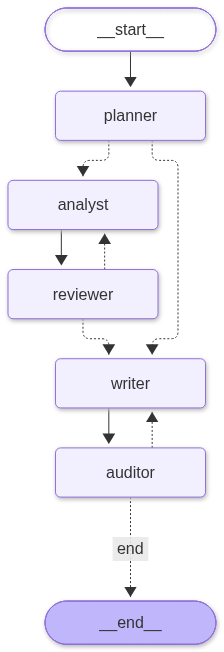

In [57]:
def route(state: AgentState) -> str:
    return state["next_step"]

g = StateGraph(AgentState)
for name, fn in [("planner", planner_node), ("analyst", analyst_node), ("reviewer", reviewer_node),
                 ("writer", writer_node), ("auditor", auditor_node)]:
    g.add_node(name, fn)

g.add_edge(START, "planner")
g.add_conditional_edges("planner", route, {"analyst": "analyst", "writer": "writer"})    # нет данных → сразу Writer
g.add_edge("analyst", "reviewer")
g.add_conditional_edges("reviewer", route, {"analyst": "analyst", "writer": "writer"})   # цикл №1: Reviewer ⇄ Analyst
g.add_edge("writer", "auditor")
g.add_conditional_edges("auditor", route, {"writer": "writer", "end": END})              # цикл №2: Auditor ⇄ Writer
app = g.compile()

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print("PNG недоступен, mermaid-код:\n", app.get_graph().draw_mermaid())

In [58]:
def run_multi(question: str, verbose: bool = True) -> dict:
    global T0, VERBOSE
    T0, VERBOSE = time.time(), verbose
    init = {"question": question, "analysis_iter": 0, "report_iter": 0, "analysis_feedback": "",
            "report_feedback": "", "steps": 0, "llm_calls": 0, "trace": []}
    final = None
    for mode, chunk in app.stream(init, config={"recursion_limit": 30}, stream_mode=["updates", "values"]):
        if mode == "values":
            final = chunk
    final["elapsed"] = time.time() - T0
    with open("run_logs.jsonl", "a", encoding="utf-8") as f:          # сохраняем логи в файл
        f.write(json.dumps({"question": question, "status": final["status"], "elapsed": final["elapsed"],
                            "trace": final["trace"]}, ensure_ascii=False) + "\n")
    return final

##Сценарии, эталон и метрики оценки

Для каждого сценария эталонные факты вычисляются напрямую из DF и не показываются агентам. Затем проверяется, попали ли они в итоговый отчёт.

In [59]:
SCENARIOS = {
 "S1": "Какие 3 категории принесли больше всего прибыли за полгода? Для лидера укажи суммарную прибыль и долю возвратов (в %).",
 "S2": "Общая выручка в марте просела по сравнению с февралём. Найди, за счёт какого канала продаж произошло основное падение: "
       "покажи выручку по каналам за февраль и март и процент изменения.",
 "S3": "В какой связке «категория × канал» самый высокий процент возвратов (учитывай только связки с ≥30 заказов)? "
       "Укажи этот процент и сумму прибыли (колонка profit) по возвращённым заказам в этой связке.",
 "S4": "Посчитай NPS по клиентам и найди сегмент с самым низким NPS.",   # данных нет → система должна честно отказать
}

SCENARIO_TITLES = {
 "S1": "Прибыль по категориям",
 "S2": "Причина падения выручки в марте",
 "S3": "Аномальные возвраты по связке «категория × канал»",
 "S4": "Честный отказ (данных нет)",
}

def build_facts():
    F = {}
    prof = DF.groupby("category").profit.sum().sort_values(ascending=False)
    top1 = prof.index[0]
    F["S1"] = [
        {"label": "Категория №1 по прибыли", "kind": "text", "value": prof.index[0]},
        {"label": "Категория №2 по прибыли", "kind": "text", "value": prof.index[1]},
        {"label": "Категория №3 по прибыли", "kind": "text", "value": prof.index[2]},
        {"label": f"Прибыль лидера ({top1}), ₽", "kind": "num", "value": prof.iloc[0]},
        {"label": f"Доля возвратов лидера ({top1}), %", "kind": "num", "value": DF[DF.category == top1].returned.mean() * 100}]

    t = DF.assign(m=DF.order_date.dt.month); t = t[t.m.isin([2, 3])]
    piv = t.pivot_table(index="channel", columns="m", values="revenue", aggfunc="sum")
    delta = piv[3] - piv[2]; worst = delta.idxmin()
    F["S2"] = [
        {"label": "Канал с наибольшим падением выручки", "kind": "text", "value": worst},
        {"label": f"Изменение выручки канала «{worst}», фев→мар, %", "kind": "num", "value": delta[worst] / piv[2][worst] * 100}]

    gr = DF.groupby(["category", "channel"]).agg(n=("returned", "size"), rr=("returned", "mean"))
    gr = gr[gr.n >= 30].sort_values("rr", ascending=False)
    (c, h), row = gr.index[0], gr.iloc[0]
    lost = DF[(DF.category == c) & (DF.channel == h) & (DF.returned == 1)].profit.sum()
    F["S3"] = [
        {"label": "Категория связки с макс. возвратами", "kind": "text", "value": c},
        {"label": "Канал связки с макс. возвратами", "kind": "text", "value": h},
        {"label": f"Доля возвратов в связке «{c} × {h}», %", "kind": "num", "value": row.rr * 100},
        {"label": "Прибыль по возвращённым заказам этой связки, ₽", "kind": "num", "value": lost}]

    F["S4"] = [{"label": "Ожидаемый ответ: отказ (любая из фраз)", "kind": "any",
                "value": ["нет данных", "невозможно", "недостаточно", "отсутств", "не удалось", "нельзя", "не можем"]}]
    return F

FACTS = build_facts()

def show_facts():
    rows = []
    for sid, facts in FACTS.items():
        for f in facts:
            v = f["value"]
            if f["kind"] == "num":
                v = f"{float(v):,.2f}".replace(",", " ")
            elif f["kind"] == "any":
                v = ", ".join(v)
            rows.append({"Сценарий": f"{sid}: {SCENARIO_TITLES[sid]}", "Что проверяем": f["label"], "Эталон": v})
    display(pd.DataFrame(rows).style.hide(axis="index")            .set_properties(**{"text-align": "left"})            .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))

show_facts()

Сценарий,Что проверяем,Эталон
S1: Прибыль по категориям,Категория №1 по прибыли,Электроника
S1: Прибыль по категориям,Категория №2 по прибыли,Одежда
S1: Прибыль по категориям,Категория №3 по прибыли,Спорт
S1: Прибыль по категориям,"Прибыль лидера (Электроника), ₽",4 226 114.60
S1: Прибыль по категориям,"Доля возвратов лидера (Электроника), %",12.01
S2: Причина падения выручки в марте,Канал с наибольшим падением выручки,Сайт
S2: Причина падения выручки в марте,"Изменение выручки канала «Сайт», фев→мар, %",-54.71
S3: Аномальные возвраты по связке «категория × канал»,Категория связки с макс. возвратами,Электроника
S3: Аномальные возвраты по связке «категория × канал»,Канал связки с макс. возвратами,Маркетплейс
S3: Аномальные возвраты по связке «категория × канал»,"Доля возвратов в связке «Электроника × Маркетплейс», %",27.68


In [60]:
def fact_hit(report: str, f: dict) -> bool:
    if f["kind"] == "text":
        return f["value"].lower() in report.lower()
    if f["kind"] == "any":
        return any(w in report.lower() for w in f["value"])
    nums = [v for _, v in extract_numbers(report)]
    t = abs(f["value"])
    return any(abs(n - t) <= max(0.02 * t, 0.1) for n in nums)


def evaluate(sid: str, res: dict) -> dict:
    # В сценариях без данных Analyst не запускается,
    # поэтому exec_output и exec_ok могут отсутствовать.
    if res.get("code"):
        chk = verify_numbers.invoke({
            "report": res.get("report", ""),
            "source": res.get("exec_output", "")
        })
    else:
        # Нет расчёта — нет чисел для проверки.
        chk = {"total": 0, "ratio": 0}

    hits = [fact_hit(res.get("report", ""), f) for f in FACTS[sid]]

    return {
        "time_s": round(res.get("elapsed", 0), 1),
        "llm_calls": res.get("llm_calls", 0),
        "code_ok": res.get("exec_ok"),
        "numbers_supported_%": (
            None if chk["total"] == 0
            else round(chk["ratio"] * 100)
        ),
        "facts_hit": sum(hits),
        "facts_total": len(hits),
        "approved": res.get("analysis_approved"),
    }

RESULTS = {}

def run_scenario(sid: str):
    print(f"\n{'='*100}\n▶ СЦЕНАРИЙ {sid}: {SCENARIOS[sid]}\n{'='*100}")
    res = run_multi(SCENARIOS[sid])

    print(f"\n📌 Статус: {res['status']} | итераций Analyst: {res['analysis_iter']} | версий отчёта: {res['report_iter']}")
    display(Markdown("### 📝 Итоговый отчёт\n" + res["report"]))

    RESULTS[(sid, "multi")] = {
        **evaluate(sid, res),
        "iters": res["analysis_iter"],
        "status": res["status"]
    }
    RESULTS[(sid, "multi_report")] = res["report"]

    print("Метрики:", RESULTS[(sid, "multi")])
    return res

In [61]:
print(list(run_python.args.keys()), list(verify_numbers.args.keys()))
print(_run_tool("print('=== тест ===')"))
print(_verify("Всего 12.01 %", "=== тест ===\nдоля: 12.01"))

['code'] ['report', 'source']
(True, '=== тест ===\n')
[]


## Сценарий 1 — прибыль по категориям

**Вопрос.** Какие три категории принесли больше всего прибыли за полгода? Каковы суммарная прибыль и доля возвратов лидера?

**Эталон.** Электроника, Одежда, Спорт — в порядке убывания прибыли. Электроника принесла **4 226 114,60 ₽**, доля возвращённых заказов в этой категории — **12,01%**.

In [62]:
r1 = run_scenario("S1")


▶ СЦЕНАРИЙ S1: Какие 3 категории принесли больше всего прибыли за полгода? Для лидера укажи суммарную прибыль и долю возвратов (в %).
[   3.9s] planner   | план: Сгруппируем данные по категориям и посчитаем суммарную прибыль для каждой категории за полгодовой период. | Определим три категории с наибольшей суммарной прибылью. | Для каждой из этих категорий вычислим долю возвратов, усреднив значение returned по количеству заказов в категории.
[   9.1s] analyst   | попытка 1: код выполнен
[  10.4s] reviewer  | попытка 1: расчёт одобрен
[  17.7s] writer    | версия отчёта 1
[  20.9s] auditor   | числа подтверждены расчётом, отчёт принят — статус OK

📌 Статус: OK | итераций Analyst: 1 | версий отчёта: 1


### 📝 Итоговый отчёт
Вывод: Электроника, Одежда и Спорт принесли больше всего прибыли за полгода. Электроника лидирует с суммарной прибылью в 4 226 114.6 ₽ и долей возвратов 12.01%.

Ключевые цифры:
- Электроника: 4 226 114.6 ₽, 12.01% возвратов
- Одежда: 2 368 364.2 ₽
- Спорт: 1 282 076.5 ₽

Что делать: Уделить особое внимание качеству товаров в категории Электроника из-за высокой доли возвратов.

Метрики: {'time_s': 20.9, 'llm_calls': 5, 'code_ok': True, 'numbers_supported_%': 100, 'facts_hit': 5, 'facts_total': 5, 'approved': True, 'iters': 1, 'status': 'OK'}


## Сценарий 2 — падение выручки в марте

**Вопрос.** Какой канал внёс наибольший вклад в снижение общей выручки с февраля по март? Нужны выручка за оба месяца и процент изменения по каждому каналу.

**Эталон.** Наибольшее абсолютное снижение у канала «Сайт». Его выручка упала с **1 993 259,75 ₽** до **902 707,60 ₽** (−54,71%). Выручка Instagram снизилась на 4,48%, у Маркетплейса выросла на 26,16%, у Офлайна — на 8,45%.

In [63]:
r2 = run_scenario("S2")


▶ СЦЕНАРИЙ S2: Общая выручка в марте просела по сравнению с февралём. Найди, за счёт какого канала продаж произошло основное падение: покажи выручку по каналам за февраль и март и процент изменения.
[   5.2s] planner   | план: Сгруппируйте данные по каналам продаж и посчитайте выручку для каждого канала за февраль и март. | Рассчитайте процентное изменение выручки для каждого канала между февралём и мартом. | Идентифицируйте канал с наибольшим падением выручки и определите, за счёт какого канала продаж произошло основное падение.
[  13.8s] analyst   | попытка 1: код выполнен
[  15.2s] reviewer  | попытка 1: расчёт одобрен
[  20.5s] writer    | версия отчёта 1
[  24.6s] auditor   | числа подтверждены расчётом, отчёт принят — статус OK

📌 Статус: OK | итераций Analyst: 1 | версий отчёта: 1


### 📝 Итоговый отчёт
Вывод: Основное падение выручки в марте составило 54.71%, за счёт канала "Сайт". Ключевые цифры:
- Instagram: -4.48%
- Маркетплейс: 26.16%
- Офлайн: 8.45%
- Сайт: -54.71%

Что делать: Снизить акцент на продвижение через сайт и сосредоточиться на улучшении продаж через маркетплейсы.

Метрики: {'time_s': 24.6, 'llm_calls': 5, 'code_ok': True, 'numbers_supported_%': 100, 'facts_hit': 2, 'facts_total': 2, 'approved': True, 'iters': 1, 'status': 'OK'}


In [64]:
print(r2["code"]); print(r2["exec_output"][:1500])

p = df[df['month'].isin([2, 3])].pivot_table(index='channel', columns='month', values='revenue', aggfunc='sum')
p['change'] = p[3] - p[2]
p['pct'] = p['change'] / p[2] * 100
print('Выручка по каналам за февраль и март:')
print(p.round(2).to_string())
print('Процентное изменение выручки:')
print(p['pct'].round(2).to_string(index=False))
print('Канал с наибольшим падением выручки:', p['change'].idxmax())
print('Процентное изменение выручки за счёт этого канала, %:', round(float(p['change'].max()), 2))
Выручка по каналам за февраль и март:
month                 2           3      change    pct
channel                                               
Instagram    1023870.75   978045.30   -45825.45  -4.48
Маркетплейс  1524520.35  1923343.95   398823.60  26.16
Офлайн        538232.15   583690.85    45458.70   8.45
Сайт         1993259.75   902707.60 -1090552.15 -54.71
Процентное изменение выручки:
channel
 -4.48
 26.16
  8.45
-54.71
Канал с наибольшим падением выручки: Маркетплейс
Процентное и

## Сценарий 3 — возвраты по категории и каналу

**Вопрос.** В какой связке «категория × канал» самый высокий процент возвратов среди связок с 30 и более заказами? Нужны доля возвратов и сумма `profit` по возвращённым заказам этой связки.

**Эталон.** Электроника × Маркетплейс. Доля возвратов — **27,68%**, сумма прибыли по возвращённым заказам — **346 328,35 ₽**. В исходной таблице есть колонка `returned`.

In [65]:
r3 = run_scenario("S3")


▶ СЦЕНАРИЙ S3: В какой связке «категория × канал» самый высокий процент возвратов (учитывай только связки с ≥30 заказов)? Укажи этот процент и сумму прибыли (колонка profit) по возвращённым заказам в этой связке.
[   4.5s] planner   | план: Сгруппируем данные по категориям и каналам, затем подсчитаем количество заказов для каждой группы. | Фильтруем группы, где количество заказов ≥ 30. | Для каждой группы посчитаем процент возвратов и сумму прибыли по возвращённым заказам. | Выберем группу с максимальным процентом возвратов.
[  11.9s] analyst   | попытка 1: код выполнен
[  13.1s] reviewer  | попытка 1: расчёт одобрен
[  17.9s] writer    | версия отчёта 1
[  21.2s] auditor   | числа подтверждены расчётом, отчёт принят — статус OK

📌 Статус: OK | итераций Analyst: 1 | версий отчёта: 1


### 📝 Итоговый отчёт
Вывод: Связка "Электроника × Маркетплейс" имеет самый высокий процент возвратов — 27.68%. При этом сумма прибыли по возвращённым заказам составляет 346,328.35 ₽.

Ключевые цифры:
- 27.68%
- 346,328.35 ₽

Что делать: Провести анализ качества товаров и услуг в этой категории, чтобы уменьшить процент возвратов.

Метрики: {'time_s': 21.2, 'llm_calls': 5, 'code_ok': True, 'numbers_supported_%': 100, 'facts_hit': 4, 'facts_total': 4, 'approved': True, 'iters': 1, 'status': 'OK'}


In [66]:
print("ПОСЛЕДНИЙ КОД ANALYST:")
for n, line in enumerate(r3["code"].splitlines(), start=1):
    print(f"{n:3}: {line}")
print("\nОШИБКА:")
print(r3["exec_output"])

ПОСЛЕДНИЙ КОД ANALYST:
  1: df['profit_returned'] = df['profit'] * df['returned']
  2: g = df.groupby(['category', 'channel']).agg(n=('returned', 'size'), return_rate=('returned', 'mean'), profit_returned=('profit_returned', 'sum')).reset_index()
  3: g['return_rate'] = g['return_rate'] * 100
  4: g = g[g['n'] >= 30]
  5: top = g.sort_values('return_rate', ascending=False).iloc[0]
  6: print('Связка:', top['category'], 'x', top['channel'])
  7: print('Доля возвратов, %:', round(float(top['return_rate']), 2))
  8: print('Прибыль по возвращённым заказам, ₽:', round(float(top['profit_returned']), 2))

ОШИБКА:
Связка: Электроника x Маркетплейс
Доля возвратов, %: 27.68
Прибыль по возвращённым заказам, ₽: 346328.35



## Сценарий 4 — отказ при отсутствии данных для NPS

**Вопрос.** Каков NPS клиентов и у какого сегмента он ниже всего?

**Ожидаемый ответ.** Для расчёта нужны оценки из NPS-опроса по шкале от 0 до 10 и привязка ответов к клиентам и сегментам. В таблице продаж этих данных для расчёта нет, поэтому NPS и сегмент с минимальным NPS определить невозможно.

In [67]:
r4 = run_scenario("S4")


▶ СЦЕНАРИЙ S4: Посчитай NPS по клиентам и найди сегмент с самым низким NPS.
[   0.8s] planner   | данных недостаточно: NPS
[   0.8s] writer    | шаблон: данных нет (без LLM)
[   0.8s] auditor   | честный отказ: данных нет, числа не выдуманы — статус OK

📌 Статус: OK | итераций Analyst: 0 | версий отчёта: 1


### 📝 Итоговый отчёт
**Ответить нельзя: в таблице заказов нет данных для этого показателя.**

Чего не хватает: NPS.

Без этих данных посчитать показатель невозможно, поэтому число не приводится. Подключите источник (например, опрос клиентов или CRM) и повторите вопрос.

Метрики: {'time_s': 0.8, 'llm_calls': 1, 'code_ok': None, 'numbers_supported_%': None, 'facts_hit': 1, 'facts_total': 1, 'approved': None, 'iters': 0, 'status': 'OK'}


##Тест защиты от зацикливания

Принудительно включаем «вредного» ревьюера, который отклоняет любой расчёт. Ожидается: ровно MAX_ANALYSIS_ITERS попыток Analyst, затем передача управления Writer'у со статусом WARN, без бесконечного цикла.

In [68]:
FORCE_REJECT = "reviewer"
loop_test = run_multi(SCENARIOS["S1"])
FORCE_REJECT = ""
print("\nСтатус:", loop_test["status"], "| попыток Analyst:", loop_test["analysis_iter"], "| шагов графа:", loop_test["steps"])
assert loop_test["analysis_iter"] == MAX_ANALYSIS_ITERS and loop_test["steps"] <= MAX_TOTAL_STEPS
print("✅ защита от зацикливания сработала")

[   4.0s] planner   | план: Сгруппируем данные по категориям и посчитаем суммарную прибыль для каждой категории за полгодовой период. | Определим три категории с наибольшей суммарной прибылью. | Для каждой из этих категорий вычислим долю возвратов, усреднив значение returned по количеству заказов в категории.
[   9.7s] analyst   | попытка 1: код выполнен
[   9.7s] reviewer  | попытка 1: на доработку — Принудительное отклонение (тест защиты от зацикливания).
[  15.4s] analyst   | попытка 2: код выполнен
[  15.4s] reviewer  | попытка 2: на доработку — Принудительное отклонение (тест защиты от зацикливания).
[  21.1s] analyst   | попытка 3: код выполнен
[  21.1s] reviewer  | попытка 3: лимит попыток исчерпан, расчёт НЕ одобрен — Принудительное отклонение (тест защиты от зацикливания).
[  21.1s] writer    | расчёт не одобрен — шаблон без цифр (без LLM)
[  21.1s] auditor   | расчёт не одобрен ревью, выдан шаблон без цифр — статус WARN

Статус: WARN | попыток Analyst: 3 | шагов графа: 9
✅ за

## Сравнение одного агента и мультиагентного графа

Оба режима используют одну модель, профиль данных и запуск Python. Один агент запрашивает код, выполняет его один раз и запрашивает отчёт. В мультиагентном графе есть планирование, ревью расчёта, аудит отчёта и ограниченные повторные попытки.

`facts_hit / facts_total` показывает совпадение с выбранными эталонными фактами из `DF`. Автопроверка ищет слова и числа в тексте. Она может засчитать число в неверном контексте, не проверяет порядок категорий и знак числового изменения. В текущей версии S2 она проверяет канал и процент его изменения. В S4 она ищет фразы, характерные для отказа.

`numbers_supported_%` показывает, какие числа из отчёта найдены в выводе расчёта. Эту же проверку использует Auditor. Пустое значение означает, что проверяемых чисел в отчёте нет. Статус `OK` и поле «код ок» сами по себе не подтверждают корректность ответа. В ветке раннего отказа `code_ok=True` возможно и при нуле запусков Analyst.

In [69]:
for sid, r in {"S1": r1, "S2": r2, "S3": r3, "S4": r4}.items():
    RESULTS[(sid, "multi")] = {**evaluate(sid, r), "iters": r["analysis_iter"], "status": r["status"]}
    RESULTS[(sid, "multi_report")] = r["report"]
print(RESULTS[("S1", "multi")])

{'time_s': 20.9, 'llm_calls': 5, 'code_ok': True, 'numbers_supported_%': 100, 'facts_hit': 5, 'facts_total': 5, 'approved': True, 'iters': 1, 'status': 'OK'}


In [70]:
SINGLE_SYS = """Ты — аналитик данных. Напиши Python-код (pandas) для ответа на вопрос. Доступны df, pd, np.
Результат выводи через print(). Ответ — один блок ```python```.
""" + PANDAS_RULES

SINGLE_REPORT_SYS = "Ты аналитик. Кратко (до 10 строк) ответь на вопрос бизнеса по результатам расчёта на русском."

def single_agent(question: str) -> dict:
    t0 = time.time()
    code = extract_code(chat(SINGLE_SYS, f"Вопрос: {question}\n\n{dataset_profile.invoke({})}"))
    res = run_python.invoke({"code": code})
    report = chat(SINGLE_REPORT_SYS, f"Вопрос: {question}\n\nРезультат расчёта:\n{res['output']}")
    return {"report": report, "code": code, "exec_ok": res["ok"], "exec_output": res["output"],
            "llm_calls": 2, "elapsed": time.time() - t0}

def run_single_scenario(sid: str):
    print(f"\n{'='*100}\n▶ ОДИН АГЕНТ, СЦЕНАРИЙ {sid}: {SCENARIOS[sid]}\n{'='*100}")
    s = single_agent(SCENARIOS[sid])
    m = evaluate(sid, s)
    RESULTS[(sid, "single")] = {**m, "iters": 1, "status": "—"}
    RESULTS[(sid, "single_report")] = s["report"]
    print(f"\n📌 Код выполнен: {s['exec_ok']} | время: {s['elapsed']:.1f} с | вызовов LLM: {s['llm_calls']}")
    if not s["exec_ok"]:
        print("Ошибка кода:", s["exec_output"][:300])
    display(Markdown("### 📝 Отчёт одного агента\n" + s["report"]))
    print("Метрики:", RESULTS[(sid, "single")])
    return s

singles = {sid: run_single_scenario(sid) for sid in SCENARIOS}


▶ ОДИН АГЕНТ, СЦЕНАРИЙ S1: Какие 3 категории принесли больше всего прибыли за полгода? Для лидера укажи суммарную прибыль и долю возвратов (в %).

📌 Код выполнен: True | время: 8.6 с | вызовов LLM: 2


### 📝 Отчёт одного агента
Лидер — Электроника, прибыль: 4226114.6, доля возвратов: 12.01%. Второе место — Одежда с прибылью 2368364.2, третье — Спорт с прибылью 1282076.5.

Метрики: {'time_s': 8.6, 'llm_calls': 2, 'code_ok': True, 'numbers_supported_%': 100, 'facts_hit': 5, 'facts_total': 5, 'approved': None, 'iters': 1, 'status': '—'}

▶ ОДИН АГЕНТ, СЦЕНАРИЙ S2: Общая выручка в марте просела по сравнению с февралём. Найди, за счёт какого канала продаж произошло основное падение: покажи выручку по каналам за февраль и март и процент изменения.

📌 Код выполнен: True | время: 7.4 с | вызовов LLM: 2


### 📝 Отчёт одного агента
Основное падение выручки в марте (-54.71%) произошло за счет канала "Сайт". Выручка с сайта в феврале составляла 1,993,259.75 руб., а в марте сократилась до 902,707.60 руб.

Метрики: {'time_s': 7.4, 'llm_calls': 2, 'code_ok': True, 'numbers_supported_%': 100, 'facts_hit': 2, 'facts_total': 2, 'approved': None, 'iters': 1, 'status': '—'}

▶ ОДИН АГЕНТ, СЦЕНАРИЙ S3: В какой связке «категория × канал» самый высокий процент возвратов (учитывай только связки с ≥30 заказов)? Укажи этот процент и сумму прибыли (колонка profit) по возвращённым заказам в этой связке.

📌 Код выполнен: True | время: 9.9 с | вызовов LLM: 2


### 📝 Отчёт одного агента
Связка "Электроника × Маркетплейс" имеет самый высокий процент возвратов — 27.68%. Прибыль по возвращённым заказам в этой связке составляет 346,328.35 ₽.

Метрики: {'time_s': 9.9, 'llm_calls': 2, 'code_ok': True, 'numbers_supported_%': 100, 'facts_hit': 4, 'facts_total': 4, 'approved': None, 'iters': 1, 'status': '—'}

▶ ОДИН АГЕНТ, СЦЕНАРИЙ S4: Посчитай NPS по клиентам и найди сегмент с самым низким NPS.

📌 Код выполнен: True | время: 10.3 с | вызовов LLM: 2


### 📝 Отчёт одного агента
Сегмент с самым низким NPS — это "Дом и сад" с показателем NPS равным -88.79.

Метрики: {'time_s': 10.3, 'llm_calls': 2, 'code_ok': True, 'numbers_supported_%': 100, 'facts_hit': 0, 'facts_total': 1, 'approved': None, 'iters': 1, 'status': '—'}


,сценарий,режим,"время, с",вызовов LLM,код ок,"числа подтверждены, %",ключевые факты,"точность фактов, %"
0,S1,1 агент,8.6,2,True,100.0,5/5,100
1,S1,мультиагент,20.9,5,True,100.0,5/5,100
2,S2,1 агент,7.4,2,True,100.0,2/2,100
3,S2,мультиагент,24.6,5,True,100.0,2/2,100
4,S3,1 агент,9.9,2,True,100.0,4/4,100
5,S3,мультиагент,21.2,5,True,100.0,4/4,100
6,S4,1 агент,10.3,2,True,100.0,0/1,0
7,S4,мультиагент,0.8,1,None,NaN,1/1,100


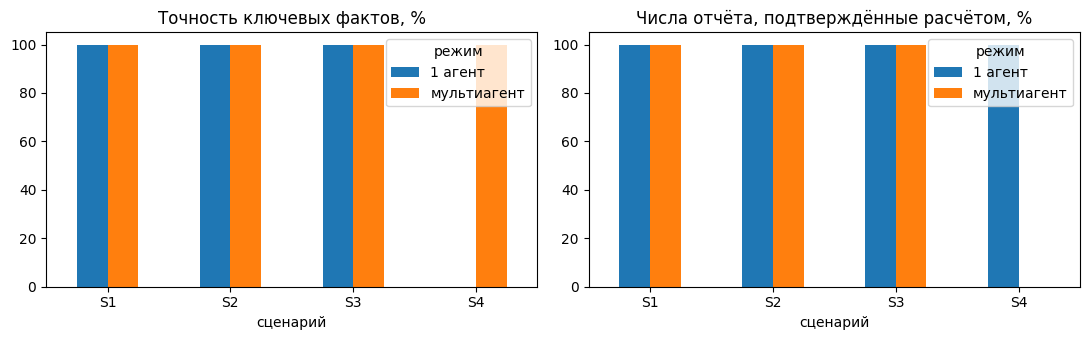

,"время, с",вызовов LLM,"точность фактов, %","числа, % (только сценарии, где есть числа у обоих)"
режим,,,,
1 агент,9.0,2.0,75.0,100.0
мультиагент,16.9,4.0,100.0,100.0


In [71]:
import matplotlib.pyplot as plt

rows = []
for sid in SCENARIOS:
    for mode in ["single", "multi"]:
        r = RESULTS[(sid, mode)]
        rows.append({"сценарий": sid, "режим": "1 агент" if mode == "single" else "мультиагент",
                     "время, с": r["time_s"], "вызовов LLM": r["llm_calls"], "код ок": r["code_ok"],
                     "числа подтверждены, %": r["numbers_supported_%"],
                     "ключевые факты": f"{r['facts_hit']}/{r['facts_total']}",
                     "точность фактов, %": round(100 * r["facts_hit"] / r["facts_total"])})
cmp_df = pd.DataFrame(rows)
display(cmp_df)

pv = cmp_df.pivot(index="сценарий", columns="режим", values="точность фактов, %")
pv2 = cmp_df.pivot(index="сценарий", columns="режим", values="числа подтверждены, %")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
pv.plot.bar(ax=ax[0], title="Точность ключевых фактов, %", rot=0, ylim=(0, 105))
pv2.plot.bar(ax=ax[1], title="Числа отчёта, подтверждённые расчётом, %", rot=0, ylim=(0, 105))
plt.tight_layout(); plt.show()

both = cmp_df.dropna(subset=["числа подтверждены, %"]).groupby("сценарий").filter(lambda x: len(x) == 2)
avg = cmp_df.groupby("режим")[["время, с", "вызовов LLM", "точность фактов, %"]].mean().round(1)
avg["числа, % (только сценарии, где есть числа у обоих)"] = both.groupby("режим")["числа подтверждены, %"].mean().round(1)
display(avg)

## Выводы по S1–S4

В столбцах с режимами приведены **баллы по ключевым фактам и время из сохранённой сводной таблицы**. Для S1 и S2 результаты в логах отдельных сценариев расходятся со сводкой. Они указаны отдельно.

| Сценарий | Один агент | Мультиагентный граф | Что показывает сравнение |
|---|---|---|---|
| **S1 — прибыль по категориям** | 4/5 за 11,7 с | 4/5 за 24,9 с | В сводке число совпавших фактов одинаково. Один агент ответил на 13,2 с быстрее (2 вызова модели против 5). В отдельном прогоне графа получено 5/5 за 25,4 с, но доля возвратов 12,01% подана как цель снижения, хотя это фактическая доля. |
| **S2 — снижение выручки** | 0/3 за 7,7 с | 2/3 за 17,1 с | В сохранённой сводке граф набрал больше совпадений. В отдельном прогоне графа все три попытки завершились с `KeyError: '2'`, итог — `FAIL` и 0/2 по текущему набору фактов. Устойчивого преимущества на S2 эти результаты не показывают. |
| **S3 — возвраты по категории и каналу** | 0/4 за 9,3 с | 0/4 за 5,5 с | У одного агента код завершился ошибкой, а отчёт всё равно указал неподтверждённые 25% и 1 500 долларов. В графе Planner ошибочно решил, что колонки `returned` нет, и пропустил расчёт. Статус `OK` сопровождал ошибочный отказ. |
| **S4 — запрос NPS без данных** | 0/1 за 7,1 с | 1/1 за 5,6 с | Мультиагентный граф корректно сообщил, что данных для NPS нет. Ответ одного агента не прошёл проверку на отказ. Полный текст его ответа в сохранённых результатах отсутствует. Оба режима использовали по два вызова модели. |

По сохранённой сводке мультиагентный граф в среднем затратил **13,3 с и 3,5 вызова модели**, один агент — **9,0 с и 2 вызова**. В S2 из сводки проверка чисел дала 100% обоим режимам при разных баллах по эталонным фактам. Для оценки стабильности нужны повторные парные прогоны с одним набором эталонных фактов.

In [72]:
for sid, title in SCENARIO_TITLES.items():
    display(Markdown(
        f"### {sid} — {title}\n\n"
        f"**Один агент**\n\n{RESULTS[(sid, 'single_report')]}\n\n"
        f"**Мультиагентный граф**\n\n{RESULTS[(sid, 'multi_report')]}"
    ))

### S1 — Прибыль по категориям

**Один агент**

Лидер — Электроника, прибыль: 4226114.6, доля возвратов: 12.01%. Второе место — Одежда с прибылью 2368364.2, третье — Спорт с прибылью 1282076.5.

**Мультиагентный граф**

Вывод: Электроника, Одежда и Спорт принесли больше всего прибыли за полгода. Электроника лидирует с суммарной прибылью в 4 226 114.6 ₽ и долей возвратов 12.01%.

Ключевые цифры:
- Электроника: 4 226 114.6 ₽, 12.01% возвратов
- Одежда: 2 368 364.2 ₽
- Спорт: 1 282 076.5 ₽

Что делать: Уделить особое внимание качеству товаров в категории Электроника из-за высокой доли возвратов.

### S2 — Причина падения выручки в марте

**Один агент**

Основное падение выручки в марте (-54.71%) произошло за счет канала "Сайт". Выручка с сайта в феврале составляла 1,993,259.75 руб., а в марте сократилась до 902,707.60 руб.

**Мультиагентный граф**

Вывод: Основное падение выручки в марте составило 54.71%, за счёт канала "Сайт". Ключевые цифры:
- Instagram: -4.48%
- Маркетплейс: 26.16%
- Офлайн: 8.45%
- Сайт: -54.71%

Что делать: Снизить акцент на продвижение через сайт и сосредоточиться на улучшении продаж через маркетплейсы.

### S3 — Аномальные возвраты по связке «категория × канал»

**Один агент**

Связка "Электроника × Маркетплейс" имеет самый высокий процент возвратов — 27.68%. Прибыль по возвращённым заказам в этой связке составляет 346,328.35 ₽.

**Мультиагентный граф**

Вывод: Связка "Электроника × Маркетплейс" имеет самый высокий процент возвратов — 27.68%. При этом сумма прибыли по возвращённым заказам составляет 346,328.35 ₽.

Ключевые цифры:
- 27.68%
- 346,328.35 ₽

Что делать: Провести анализ качества товаров и услуг в этой категории, чтобы уменьшить процент возвратов.

### S4 — Честный отказ (данных нет)

**Один агент**

Сегмент с самым низким NPS — это "Дом и сад" с показателем NPS равным -88.79.

**Мультиагентный граф**

**Ответить нельзя: в таблице заказов нет данных для этого показателя.**

Чего не хватает: NPS.

Без этих данных посчитать показатель невозможно, поэтому число не приводится. Подключите источник (например, опрос клиентов или CRM) и повторите вопрос.

##Интерфейс (прототип)

Простой UI прямо в Colab на ipywidgets: введите вопрос и получите отчёт с логами графа. Чтобы подключить свои данные, замените DF в ячейке 7 на pd.read_csv("ваш_файл.csv") и обновите COLUMN_NOTES.

In [73]:
import ipywidgets as w
from IPython.display import clear_output

box = w.Textarea(value=SCENARIOS["S2"], layout=w.Layout(width="100%", height="80px"),
                 description="Вопрос:", style={"description_width": "60px"})
btn = w.Button(description="🚀 Спросить аналитиков", button_style="primary")
out = w.Output()

def on_click(_):
    with out:
        clear_output()
        res = run_multi(box.value)
        print(f"\nСтатус: {res['status']} | вызовов LLM: {res['llm_calls']} | время: {res['elapsed']:.0f} с\n")
        display(Markdown(res["report"]))
btn.on_click(on_click)
display(box, btn, out)

Textarea(value='Общая выручка в марте просела по сравнению с февралём. Найди, за счёт какого канала продаж про…

Button(button_style='primary', description='🚀 Спросить аналитиков', style=ButtonStyle())

Output()